In [16]:

# ============================================================
# CELL 1: INSTALLATION, IMPORTS AND REPRODUCIBILITY
# ============================================================

!pip -q install wfdb

import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import wfdb
import tensorflow as tf

from scipy.signal import butter, sosfiltfilt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("WFDB:", wfdb.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

# Main experiment settings
FS = 360
LOWCUT = 0.5
HIGHCUT = 40.0

BEFORE = 90
AFTER = 166
WINDOW_SIZE = BEFORE + AFTER

NUM_CLASSES = 5
CLASS_NAMES = [
    "N - Normal",
    "S - Supraventricular",
    "V - Ventricular",
    "F - Fusion",
    "Q - Unknown"
]

# AAMI heartbeat mapping
AAMI_MAP = {
    "N": 0, "L": 0, "R": 0, "e": 0, "j": 0,
    "A": 1, "a": 1, "J": 1, "S": 1,
    "V": 2, "E": 2,
    "F": 3,
    "/": 4, "f": 4, "Q": 4
}

# Standard inter-patient partition.
# The four commonly excluded paced records are not included.
DS1_RECORDS = [
    "101", "106", "108", "109", "112", "114",
    "115", "116", "118", "119", "122", "124",
    "201", "203", "205", "207", "208", "209",
    "215", "220", "223", "230"
]

DS2_RECORDS = [
    "100", "103", "105", "111", "113", "117",
    "121", "123", "200", "202", "210", "212",
    "213", "214", "219", "221", "222", "228",
    "231", "232", "233", "234"
]

ALL_RECORDS = DS1_RECORDS + DS2_RECORDS

print("\nConfiguration loaded.")
print("DS1 records:", len(DS1_RECORDS))
print("DS2 records:", len(DS2_RECORDS))
print("Heartbeat window:", WINDOW_SIZE, "samples")


TensorFlow: 2.21.0
WFDB: 4.3.1
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Configuration loaded.
DS1 records: 22
DS2 records: 22
Heartbeat window: 256 samples


In [17]:

# ============================================================
# CELL 2: MIT-BIH DATASET ACQUISITION
# ============================================================

def find_dataset_folder():

    # Look for the extracted MIT-BIH database in Colab
    for header in Path("/content").rglob("100.hea"):

        folder = header.parent

        complete_count = sum(
            all(
                (folder / f"{record}.{extension}").exists()
                for extension in ["hea", "dat", "atr"]
            )
            for record in ALL_RECORDS
        )

        if complete_count >= 40:
            return folder

    return None


DATASET_DIR = find_dataset_folder()

if DATASET_DIR is not None:

    print("Existing MIT-BIH dataset found:")
    print(DATASET_DIR)

else:

    print("MIT-BIH dataset not found.")
    print("Downloading the complete database...")

    DOWNLOAD_DIR = "/content/mitdb"

    # Download the full database, including all 48 recordings
    wfdb.dl_database(
        "mitdb",
        dl_dir=DOWNLOAD_DIR
    )

    DATASET_DIR = Path(DOWNLOAD_DIR)


# Verify every record needed for the standard DS1/DS2 split
missing_records = []

for record in ALL_RECORDS:

    for extension in ["hea", "dat", "atr"]:

        file_path = DATASET_DIR / f"{record}.{extension}"

        if not file_path.exists():
            missing_records.append(str(file_path))


if missing_records:

    raise FileNotFoundError(
        "Missing required MIT-BIH files:\n"
        + "\n".join(missing_records)
    )


print("\nDataset verification successful.")
print("Dataset directory:", DATASET_DIR)
print("Selected recordings:", len(ALL_RECORDS))
print("Paced recordings excluded from this partition: 4")


Existing MIT-BIH dataset found:
/content

Dataset verification successful.
Dataset directory: /content
Selected recordings: 44
Paced recordings excluded from this partition: 4


Processing: 101
Processing: 106
Processing: 108
Processing: 109
Processing: 112
Processing: 114
Processing: 115
Processing: 116
Processing: 118
Processing: 119
Processing: 122
Processing: 124
Processing: 201
Processing: 203
Processing: 205
Processing: 207
Processing: 208
Processing: 209
Processing: 215
Processing: 220
Processing: 223
Processing: 230
Processing: 100
Processing: 103
Processing: 105
Processing: 111
Processing: 113
Processing: 117
Processing: 121
Processing: 123
Processing: 200
Processing: 202
Processing: 210
Processing: 212
Processing: 213
Processing: 214
Processing: 219
Processing: 221
Processing: 222
Processing: 228
Processing: 231
Processing: 232
Processing: 233
Processing: 234

Preprocessing completed.
DS1 shape: (51002, 256, 4)
DS2 shape: (49692, 256, 4)
Features per time step: 4
Two ECG channels + previous and next RR features


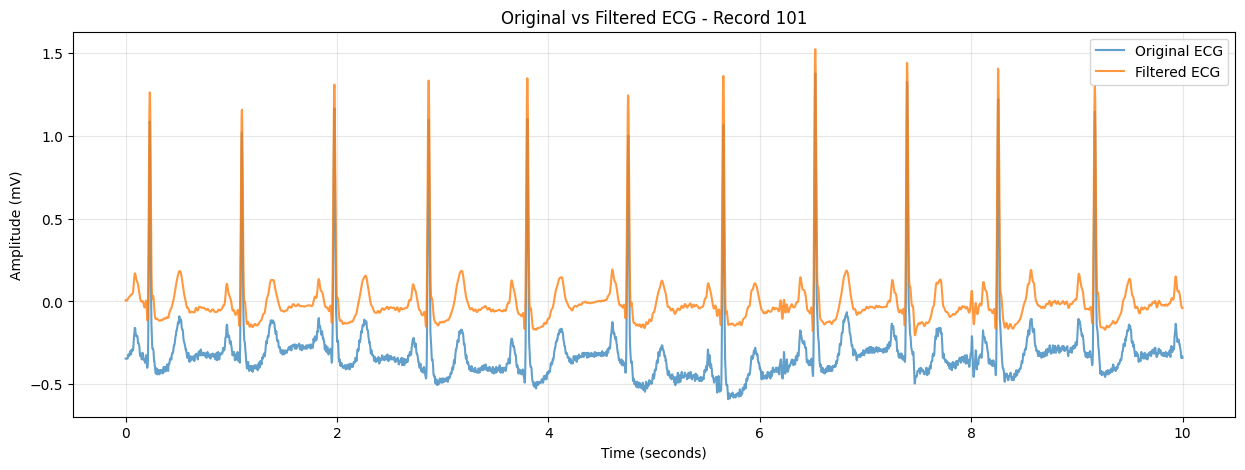

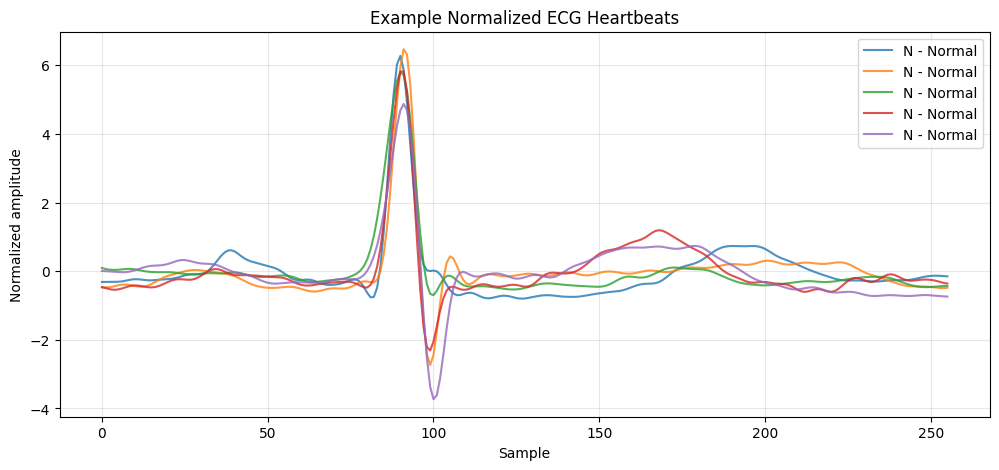

,Class,DS1,DS2
0,N - Normal,45848,44240
1,S - Supraventricular,944,1837
2,V - Ventricular,3788,3220
3,F - Fusion,414,388
4,Q - Unknown,8,7


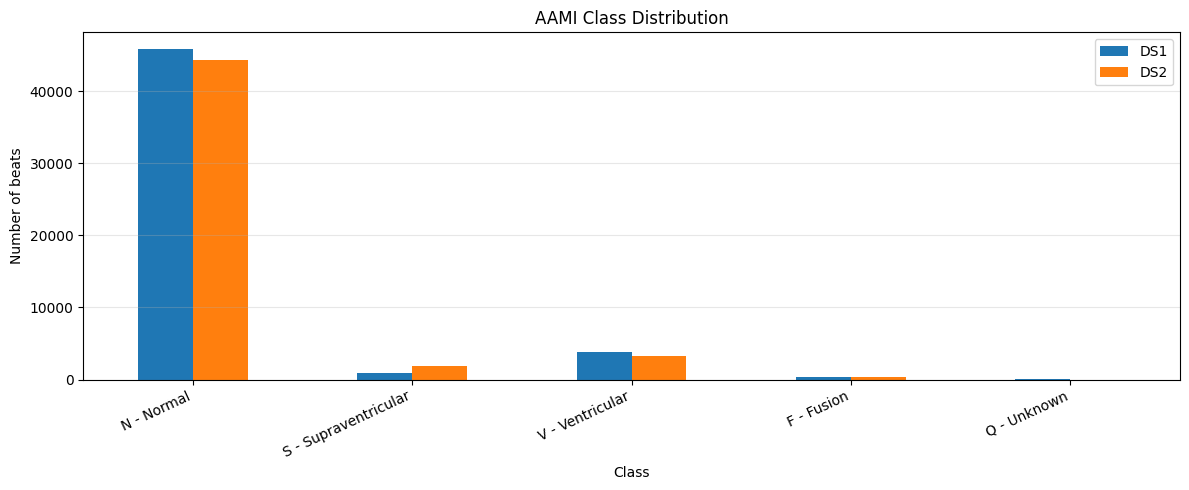

In [18]:

# ============================================================
# CELL 3: PREPROCESSING AND FEATURE EXTRACTION
# ============================================================

# ------------------------------------------------------------
# STEP 1: Butterworth bandpass filter
# ------------------------------------------------------------

def bandpass_filter(signal):

    nyquist = FS / 2

    sos = butter(
        4,
        [LOWCUT / nyquist, HIGHCUT / nyquist],
        btype="bandpass",
        output="sos"
    )

    filtered = np.zeros_like(signal, dtype=np.float32)

    for channel in range(signal.shape[1]):

        filtered[:, channel] = sosfiltfilt(
            sos,
            signal[:, channel]
        )

    return filtered


# ------------------------------------------------------------
# STEP 2: Normalize ECG channels independently
# ------------------------------------------------------------

def normalize_ecg_beat(beat):

    mean = np.mean(
        beat,
        axis=0,
        keepdims=True
    )

    std = np.std(
        beat,
        axis=0,
        keepdims=True
    )

    return ((beat - mean) / (std + 1e-8)).astype(np.float32)


# ------------------------------------------------------------
# STEP 3: Process one ECG recording
# ------------------------------------------------------------

def process_record(record_number):

    record_path = str(DATASET_DIR / record_number)

    # Load two-channel ECG signal
    record = wfdb.rdrecord(record_path)

    signal = record.p_signal[:, :2].astype(np.float32)

    if signal.shape[1] != 2:
        raise ValueError(
            f"Record {record_number} does not contain two channels."
        )

    signal = np.nan_to_num(signal)

    # Load expert annotations
    annotation = wfdb.rdann(
        record_path,
        extension="atr"
    )

    # Filter the ECG
    filtered = bandpass_filter(signal)

    # Keep only annotations mapped to AAMI heartbeat classes
    valid = [
        (int(sample), symbol)
        for sample, symbol in zip(
            annotation.sample,
            annotation.symbol
        )
        if symbol in AAMI_MAP
    ]

    if len(valid) < 3:
        return [], [], signal, filtered

    beat_positions = np.array(
        [item[0] for item in valid],
        dtype=np.int64
    )

    # RR intervals in seconds
    rr_intervals = np.diff(beat_positions) / FS

    # Record-level median RR provides a reference interval
    median_rr = np.median(rr_intervals)

    if not np.isfinite(median_rr) or median_rr <= 0:
        median_rr = 1.0

    beats = []
    labels = []

    # --------------------------------------------------------
    # STEP 4: Segment each annotated heartbeat
    # --------------------------------------------------------

    for i, (sample, symbol) in enumerate(valid):

        start = sample - BEFORE
        end = sample + AFTER

        # Ignore beats too close to signal boundaries
        if start < 0 or end > len(filtered):
            continue

        beat = filtered[start:end, :]

        if beat.shape != (WINDOW_SIZE, 2):
            continue

        # Normalize ECG morphology
        beat = normalize_ecg_beat(beat)

        # Previous and next RR intervals.
        # Use median RR for a missing edge interval.
        previous_rr = (
            rr_intervals[i - 1]
            if i > 0
            else median_rr
        )

        next_rr = (
            rr_intervals[i]
            if i < len(rr_intervals)
            else median_rr
        )

        # Express RR intervals relative to record median.
        # Clipping reduces the influence of extreme intervals.
        previous_rr = np.clip(
            previous_rr / median_rr,
            0.4,
            2.5
        )

        next_rr = np.clip(
            next_rr / median_rr,
            0.4,
            2.5
        )

        # Add RR features as two constant channels.
        # Final shape: (256 samples, 4 features)
        rr_features = np.tile(
            np.array(
                [previous_rr, next_rr],
                dtype=np.float32
            ),
            (WINDOW_SIZE, 1)
        )

        combined_beat = np.concatenate(
            [beat, rr_features],
            axis=1
        )

        beats.append(combined_beat)
        labels.append(AAMI_MAP[symbol])

    return beats, labels, signal, filtered


# ------------------------------------------------------------
# STEP 5: Process DS1 and DS2
# ------------------------------------------------------------

X_DS1_list, y_DS1_list, groups_DS1_list = [], [], []
X_DS2_list, y_DS2_list, groups_DS2_list = [], [], []

example_raw = None
example_filtered = None
example_record = None

for record_number in ALL_RECORDS:

    print("Processing:", record_number)

    beats, labels, raw, filtered = process_record(
        record_number
    )

    if record_number in DS1_RECORDS:

        X_DS1_list.extend(beats)
        y_DS1_list.extend(labels)

        groups_DS1_list.extend(
            [record_number] * len(labels)
        )

    else:

        X_DS2_list.extend(beats)
        y_DS2_list.extend(labels)

        groups_DS2_list.extend(
            [record_number] * len(labels)
        )

    if example_raw is None:

        example_raw = raw
        example_filtered = filtered
        example_record = record_number


# Convert extracted data to arrays
X_DS1 = np.asarray(X_DS1_list, dtype=np.float32)
y_DS1 = np.asarray(y_DS1_list, dtype=np.int32)
groups_DS1 = np.asarray(groups_DS1_list)

X_DS2 = np.asarray(X_DS2_list, dtype=np.float32)
y_DS2 = np.asarray(y_DS2_list, dtype=np.int32)
groups_DS2 = np.asarray(groups_DS2_list)

print("\nPreprocessing completed.")

print("DS1 shape:", X_DS1.shape)
print("DS2 shape:", X_DS2.shape)

print("Features per time step: 4")
print("Two ECG channels + previous and next RR features")


# ------------------------------------------------------------
# STEP 6: Visualize original and filtered ECG
# ------------------------------------------------------------

time_axis = np.arange(len(example_raw)) / FS

plt.figure(figsize=(15, 5))

plt.plot(
    time_axis[:3600],
    example_raw[:3600, 0],
    label="Original ECG",
    alpha=0.7
)

plt.plot(
    time_axis[:3600],
    example_filtered[:3600, 0],
    label="Filtered ECG",
    alpha=0.8
)

plt.title(f"Original vs Filtered ECG - Record {example_record}")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# ------------------------------------------------------------
# STEP 7: Visualize example heartbeat
# ------------------------------------------------------------

plt.figure(figsize=(12, 5))

sample_indices = np.linspace(
    0,
    len(X_DS1) - 1,
    min(5, len(X_DS1)),
    dtype=int
)

for index in sample_indices:

    plt.plot(
        X_DS1[index, :, 0],
        alpha=0.8,
        label=CLASS_NAMES[y_DS1[index]]
    )

plt.title("Example Normalized ECG Heartbeats")
plt.xlabel("Sample")
plt.ylabel("Normalized amplitude")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# ------------------------------------------------------------
# STEP 8: Display class distributions
# ------------------------------------------------------------

ds1_counts = np.bincount(
    y_DS1,
    minlength=NUM_CLASSES
)

ds2_counts = np.bincount(
    y_DS2,
    minlength=NUM_CLASSES
)

distribution_df = pd.DataFrame({
    "Class": CLASS_NAMES,
    "DS1": ds1_counts,
    "DS2": ds2_counts
})

display(distribution_df)

distribution_df.set_index("Class").plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("AAMI Class Distribution")
plt.ylabel("Number of beats")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Training records: [np.str_('106'), np.str_('108'), np.str_('109'), np.str_('112'), np.str_('114'), np.str_('115'), np.str_('119'), np.str_('122'), np.str_('124'), np.str_('203'), np.str_('205'), np.str_('207'), np.str_('208'), np.str_('209'), np.str_('215'), np.str_('220'), np.str_('230')]
Validation records: [np.str_('101'), np.str_('116'), np.str_('118'), np.str_('201'), np.str_('223')]
Testing records: ['100', '103', '105', '111', '113', '117', '121', '123', '200', '202', '210', '212', '213', '214', '219', '221', '222', '228', '231', '232', '233', '234']

No record overlap between train, validation and test.


,Class,Training,Validation,Testing
0,N - Normal,35844,10004,44240
1,S - Supraventricular,643,301,1837
2,V - Ventricular,2992,796,3220
3,F - Fusion,398,16,388
4,Q - Unknown,6,2,7



Moderated class weights:
N - Normal => 0.156
S - Supraventricular => 1.166
V - Ventricular => 0.541
F - Fusion => 1.482
Q - Unknown => 1.655

TRAINING: RNN


Model: "RNN_MITBIH"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 256, 4)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_2 (SimpleRNN)        │ (None, 64)             │         4,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,661 (26.02 KB)

... (11 outputs left out)

 Total params: 15,685 (61.27 KB)

 Trainable params: 15,685 (61.27 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
156/156 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.8637 - loss: 0.1989 - val_accuracy: 0.9263 - val_loss: 0.2860 - learning_rate: 5.0000e-04
Epoch 2/40
156/156 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.9372 - loss: 0.1098 - val_accuracy: 0.9007 - val_loss: 0.3127 - learning_rate: 5.0000e-04
Epoch 3/40
156/156 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.9383 - loss: 0.0965 - val_accuracy: 0.8907 - val_loss: 0.3480 - learning_rate: 5.0000e-04
Epoch 4/40
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9420 - loss: 0.0878
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
156/156 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.9434 - loss: 0.0879 - val_accuracy: 0.8949 - val_loss: 0.3414 - learning_rate: 5.0000e-04
Epoch 5/40
156/156 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.9501 - loss: 0.0821 - val_accuracy: 0.8888 - val_loss: 0.3474 - learning_rate: 2.5000e-04
Epoch 6/40
156/156 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy

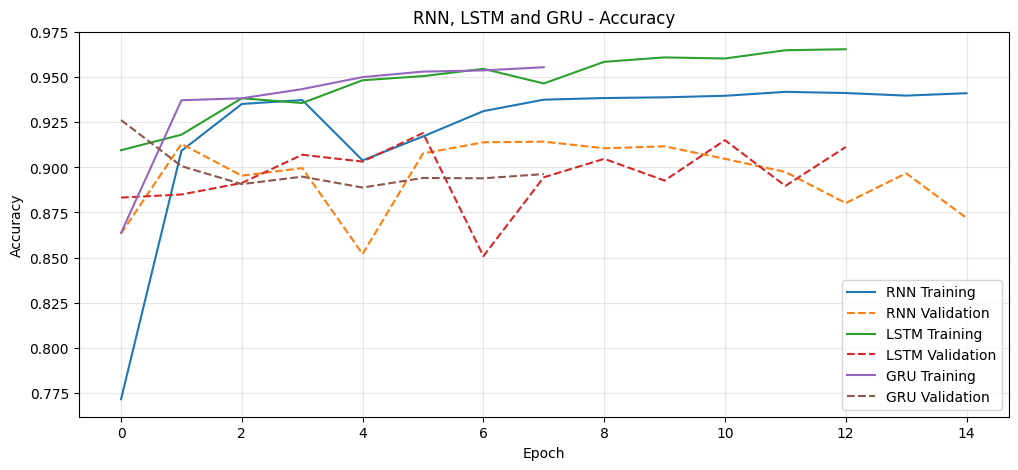

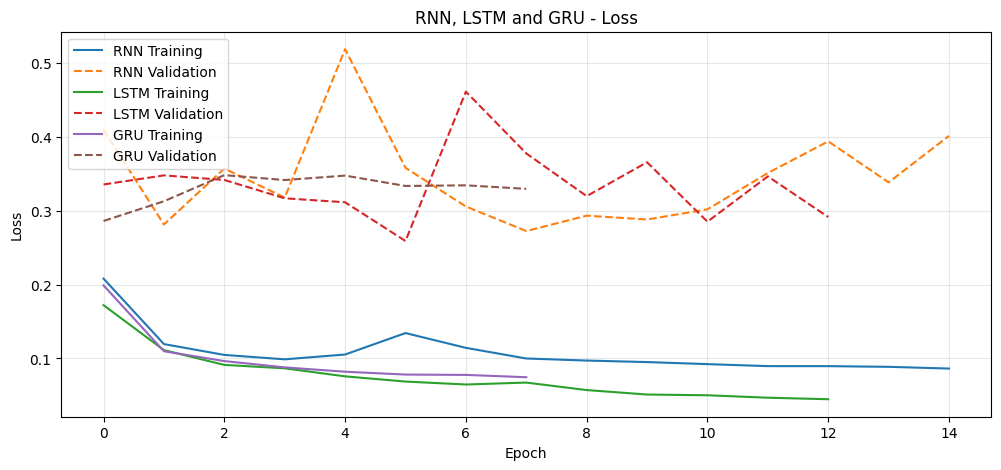


All models saved in: /content/mitbih_results


In [19]:

# ============================================================
# CELL 4: DATA SPLITTING, CLASS BALANCING AND MODEL TRAINING
# ============================================================

# ------------------------------------------------------------
# STEP 1: Find a suitable record-level validation split
# ------------------------------------------------------------

# Try multiple group splits to improve class representation.
# No individual heartbeat from a record can appear in both sets.

best_split = None
best_score = float("inf")

overall_distribution = (
    np.bincount(y_DS1, minlength=NUM_CLASSES).astype(float)
)

overall_distribution /= overall_distribution.sum()

splitter = GroupShuffleSplit(
    n_splits=300,
    test_size=0.20,
    random_state=SEED
)

for train_idx, val_idx in splitter.split(
    X_DS1,
    y_DS1,
    groups_DS1
):

    train_counts = np.bincount(
        y_DS1[train_idx],
        minlength=NUM_CLASSES
    )

    val_counts = np.bincount(
        y_DS1[val_idx],
        minlength=NUM_CLASSES
    )

    # Penalize missing classes in either set
    missing_penalty = (
        np.sum(train_counts == 0)
        + np.sum(val_counts == 0)
    ) * 100

    # Prefer validation distribution reasonably close
    # to the overall DS1 distribution
    val_distribution = (
        val_counts / max(val_counts.sum(), 1)
    )

    distribution_penalty = np.sum(
        np.abs(val_distribution - overall_distribution)
    )

    score = missing_penalty + distribution_penalty

    if score < best_score:

        best_score = score
        best_split = (train_idx, val_idx)


train_indices, val_indices = best_split

X_train = X_DS1[train_indices]
y_train = y_DS1[train_indices]

X_val = X_DS1[val_indices]
y_val = y_DS1[val_indices]

# DS2 remains untouched until final evaluation
X_test = X_DS2
y_test = y_DS2

train_records = sorted(
    set(groups_DS1[train_indices])
)

val_records = sorted(
    set(groups_DS1[val_indices])
)

print("Training records:", train_records)
print("Validation records:", val_records)
print("Testing records:", DS2_RECORDS)

assert set(train_records).isdisjoint(set(val_records))
assert set(DS1_RECORDS).isdisjoint(set(DS2_RECORDS))

print("\nNo record overlap between train, validation and test.")


# ------------------------------------------------------------
# STEP 2: Print split distributions
# ------------------------------------------------------------

split_distribution = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Training": np.bincount(y_train, minlength=NUM_CLASSES),
    "Validation": np.bincount(y_val, minlength=NUM_CLASSES),
    "Testing": np.bincount(y_test, minlength=NUM_CLASSES)
})

display(split_distribution)

for split_name, labels in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:

    missing = [
        CLASS_NAMES[i]
        for i in range(NUM_CLASSES)
        if np.sum(labels == i) == 0
    ]

    if missing:
        print(f"Warning: {split_name} has no samples for:", missing)


# ------------------------------------------------------------
# STEP 3: Calculate moderated class weights
# ------------------------------------------------------------

# Use training labels only.
# Square-root weighting is less aggressive than full
# inverse-frequency weighting and can reduce false positives.

train_counts = np.bincount(
    y_train,
    minlength=NUM_CLASSES
)

class_weights = {}

for class_id in range(NUM_CLASSES):

    if train_counts[class_id] > 0:

        weight = np.sqrt(
            len(y_train) /
            (NUM_CLASSES * train_counts[class_id])
        )

        # Limit extreme weights for very rare classes
        class_weights[class_id] = min(
            float(weight),
            5.0
        )

# Normalize weights to have mean approximately 1
weight_mean = np.mean(list(class_weights.values()))

class_weights = {
    key: value / weight_mean
    for key, value in class_weights.items()
}

print("\nModerated class weights:")

for class_id, weight in class_weights.items():

    print(
        CLASS_NAMES[class_id],
        "=>",
        round(weight, 3)
    )


# ------------------------------------------------------------
# STEP 4: Build comparable RNN, LSTM and GRU models
# ------------------------------------------------------------

def build_model(model_type):

    inputs = layers.Input(
        shape=(WINDOW_SIZE, 4)
    )

    # Only the recurrent layer changes
    if model_type == "RNN":

        x = layers.SimpleRNN(
            64,
            return_sequences=False
        )(inputs)

    elif model_type == "LSTM":

        x = layers.LSTM(
            64,
            return_sequences=False
        )(inputs)

    elif model_type == "GRU":

        x = layers.GRU(
            64,
            return_sequences=False
        )(inputs)

    else:

        raise ValueError("Choose RNN, LSTM or GRU.")

    # Identical classification head
    x = layers.Dropout(0.3)(x)

    x = layers.Dense(
        32,
        activation="relu"
    )(x)

    x = layers.Dropout(0.2)(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)

    model = Model(
        inputs=inputs,
        outputs=outputs,
        name=f"{model_type}_MITBIH"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.0005
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# ------------------------------------------------------------
# STEP 5: Identical callbacks and training configuration
# ------------------------------------------------------------

EPOCHS = 40
BATCH_SIZE = 256

def get_callbacks():

    return [

        EarlyStopping(
            monitor="val_loss",
            patience=7,
            restore_best_weights=True,
            verbose=1
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=1e-6,
            verbose=1
        )
    ]


# ------------------------------------------------------------
# STEP 6: Train all three models
# ------------------------------------------------------------

MODEL_NAMES = ["RNN", "LSTM", "GRU"]

models = {}
histories = {}

for model_name in MODEL_NAMES:

    print("\n" + "=" * 60)
    print("TRAINING:", model_name)
    print("=" * 60)

    model = build_model(model_name)

    model.summary()

    history = model.fit(
        X_train,
        y_train,

        validation_data=(
            X_val,
            y_val
        ),

        epochs=EPOCHS,
        batch_size=BATCH_SIZE,

        class_weight=class_weights,

        callbacks=get_callbacks(),

        shuffle=True,
        verbose=1
    )

    models[model_name] = model
    histories[model_name] = history

    print(model_name, "training completed.")


# ------------------------------------------------------------
# STEP 7: Plot accuracy and loss curves
# ------------------------------------------------------------

plt.figure(figsize=(12, 5))

for name, history in histories.items():

    plt.plot(
        history.history["accuracy"],
        label=f"{name} Training"
    )

    plt.plot(
        history.history["val_accuracy"],
        linestyle="--",
        label=f"{name} Validation"
    )

plt.title("RNN, LSTM and GRU - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


plt.figure(figsize=(12, 5))

for name, history in histories.items():

    plt.plot(
        history.history["loss"],
        label=f"{name} Training"
    )

    plt.plot(
        history.history["val_loss"],
        linestyle="--",
        label=f"{name} Validation"
    )

plt.title("RNN, LSTM and GRU - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# ------------------------------------------------------------
# STEP 8: Save trained models
# ------------------------------------------------------------

RESULT_DIR = "/content/mitbih_results"
os.makedirs(RESULT_DIR, exist_ok=True)

for name, model in models.items():

    model.save(
        f"{RESULT_DIR}/{name}_model.keras"
    )

print("\nAll models saved in:", RESULT_DIR)



FINAL TEST EVALUATION: RNN
195/195 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step

Accuracy: 0.8921
Macro Precision: 0.3212
Macro Recall: 0.3646
Macro F1: 0.3343
Weighted F1: 0.8882

Classification Report:

                      precision    recall  f1-score   support

          N - Normal       0.95      0.94      0.95     44240
S - Supraventricular       0.07      0.02      0.03      1837
     V - Ventricular       0.58      0.86      0.69      3220
          F - Fusion       0.00      0.01      0.00       388
         Q - Unknown       0.00      0.00      0.00         7

            accuracy                           0.89     49692
           macro avg       0.32      0.36      0.33     49692
        weighted avg       0.89      0.89      0.89     49692

Predicted class distribution:
N - Normal : 43548
S - Supraventricular : 484
V - Ventricular : 4780
F - Fusion : 880
Q - Unknown : 0

FINAL TEST EVALUATION: LSTM
195/195 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step

Accuracy: 0.8207
Macro Precision: 0.2749
M

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,RNN,0.8921,0.3212,0.3646,0.3343,0.8882
1,LSTM,0.8207,0.2749,0.3374,0.2842,0.8358
2,GRU,0.9081,0.3276,0.3536,0.3368,0.8976


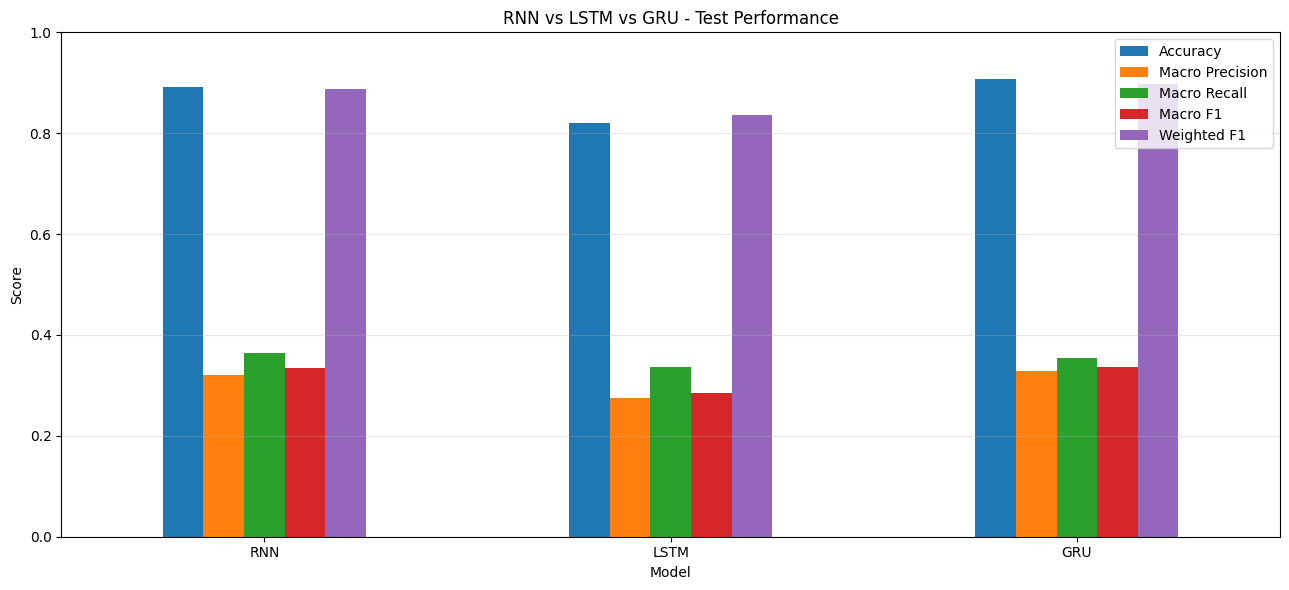

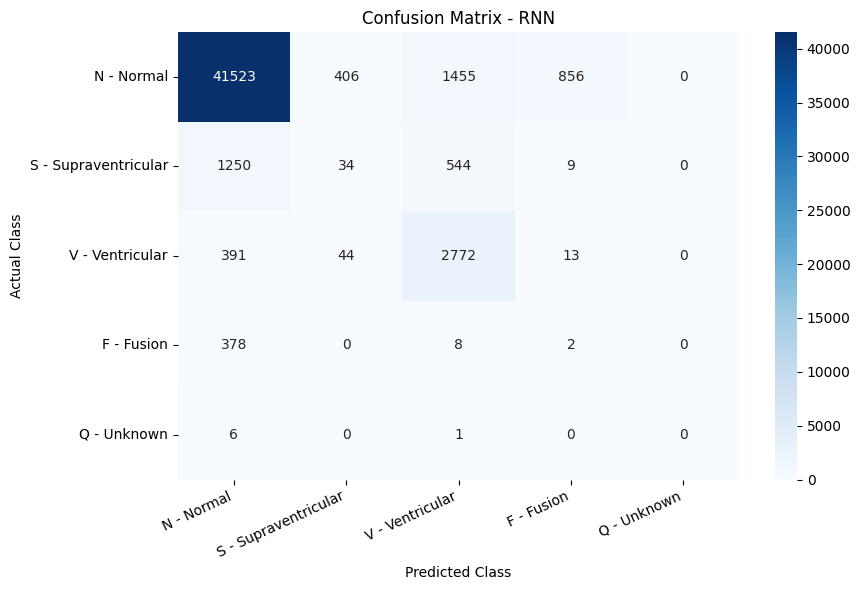

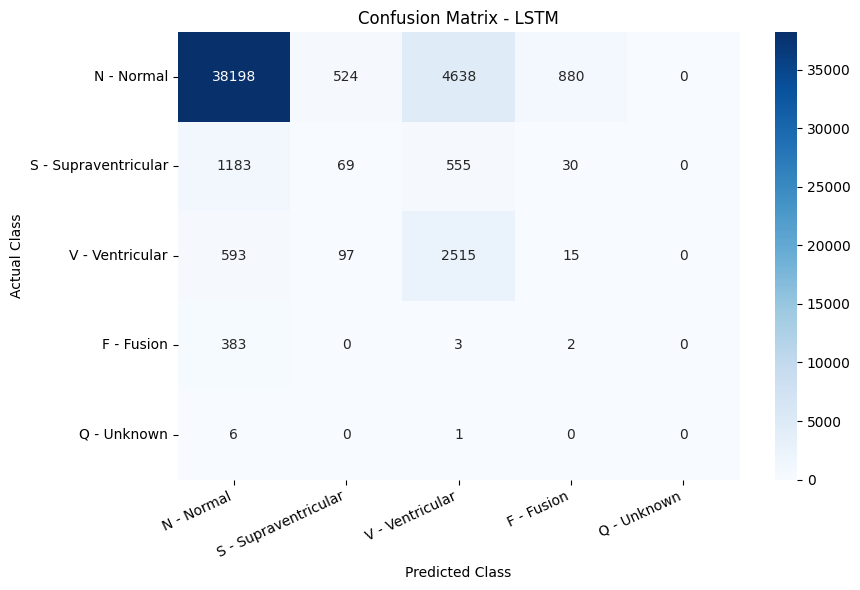

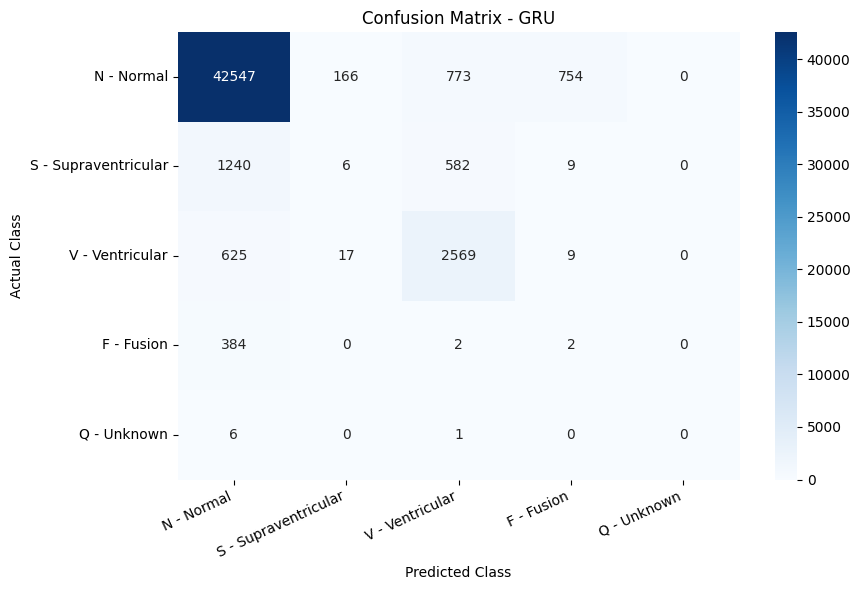


FINAL EXPERIMENT SUMMARY
Best model: GRU
Accuracy: 0.9081
Macro Precision: 0.3276
Macro Recall: 0.3536
Macro F1: 0.3368
Weighted F1: 0.8976

Results saved in: /content/mitbih_results

Saved files:
GRU_classification_report.csv
GRU_confusion_matrix.csv
GRU_model.keras
LSTM_classification_report.csv
LSTM_confusion_matrix.csv
LSTM_model.keras
RNN_classification_report.csv
RNN_confusion_matrix.csv
RNN_model.keras
model_comparison.csv


In [20]:

# ============================================================
# CELL 5: FINAL TESTING AND MODEL COMPARISON
# ============================================================

results = []
predictions = {}

# ------------------------------------------------------------
# STEP 1: Evaluate each model on DS2
# ------------------------------------------------------------

for name, model in models.items():

    print("\n" + "=" * 60)
    print("FINAL TEST EVALUATION:", name)
    print("=" * 60)

    probabilities = model.predict(
        X_test,
        batch_size=BATCH_SIZE,
        verbose=1
    )

    y_pred = np.argmax(
        probabilities,
        axis=1
    )

    predictions[name] = y_pred

    # Overall performance metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1
    })

    print("\nAccuracy:", round(accuracy, 4))
    print("Macro Precision:", round(precision, 4))
    print("Macro Recall:", round(recall, 4))
    print("Macro F1:", round(macro_f1, 4))
    print("Weighted F1:", round(weighted_f1, 4))

    # Detailed class-wise performance
    print("\nClassification Report:\n")

    print(
        classification_report(
            y_test,
            y_pred,
            labels=np.arange(NUM_CLASSES),
            target_names=CLASS_NAMES,
            zero_division=0
        )
    )

    # Show how many samples the model predicts per class
    predicted_counts = np.bincount(
        y_pred,
        minlength=NUM_CLASSES
    )

    print("Predicted class distribution:")

    for i in range(NUM_CLASSES):

        print(
            CLASS_NAMES[i],
            ":",
            predicted_counts[i]
        )


# ------------------------------------------------------------
# STEP 2: Compare all three models
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

print("\nFINAL MODEL COMPARISON")

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Macro Precision": "{:.4f}",
        "Macro Recall": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Weighted F1": "{:.4f}"
    })
)

results_df.to_csv(
    f"{RESULT_DIR}/model_comparison.csv",
    index=False
)


# ------------------------------------------------------------
# STEP 3: Plot comparison of evaluation metrics
# ------------------------------------------------------------

metric_columns = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted F1"
]

results_df.set_index("Model")[metric_columns].plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("RNN vs LSTM vs GRU - Test Performance")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="best")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# STEP 4: Generate confusion matrices
# ------------------------------------------------------------

for name, y_pred in predictions.items():

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=np.arange(NUM_CLASSES)
    )

    plt.figure(figsize=(9, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.xticks(rotation=25, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    pd.DataFrame(
        cm,
        index=CLASS_NAMES,
        columns=CLASS_NAMES
    ).to_csv(
        f"{RESULT_DIR}/{name}_confusion_matrix.csv"
    )


# ------------------------------------------------------------
# STEP 5: Save individual classification reports
# ------------------------------------------------------------

for name, y_pred in predictions.items():

    report = classification_report(
        y_test,
        y_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )

    pd.DataFrame(report).transpose().to_csv(
        f"{RESULT_DIR}/{name}_classification_report.csv"
    )


# ------------------------------------------------------------
# STEP 6: Identify the best model using macro F1
# ------------------------------------------------------------

best_index = results_df["Macro F1"].idxmax()
best_model = results_df.loc[best_index]

print("\n" + "=" * 60)
print("FINAL EXPERIMENT SUMMARY")
print("=" * 60)

print("Best model:", best_model["Model"])
print("Accuracy:", round(best_model["Accuracy"], 4))
print("Macro Precision:", round(best_model["Macro Precision"], 4))
print("Macro Recall:", round(best_model["Macro Recall"], 4))
print("Macro F1:", round(best_model["Macro F1"], 4))
print("Weighted F1:", round(best_model["Weighted F1"], 4))

print("\nResults saved in:", RESULT_DIR)

print("\nSaved files:")

for file in sorted(Path(RESULT_DIR).iterdir()):
    print(file.name)


### Results and Conclusion

Three recurrent neural network architectures—Simple RNN, LSTM and GRU—were implemented for five-class ECG heartbeat classification using the MIT-BIH Arrhythmia Database. The ECG signals were filtered using a Butterworth bandpass filter, segmented into fixed-length heartbeat windows and normalized. RR-interval features were also incorporated to provide additional temporal information.

Among the three models, GRU achieved the highest test accuracy of **90.81%**, a macro F1-score of **33.68%** and a weighted F1-score of **89.76%**. RNN achieved an accuracy of 89.21%, while LSTM achieved 82.07%.

The GRU model performed particularly well in classifying normal and ventricular heartbeats. However, performance on supraventricular, fusion and unknown heartbeat classes remained limited due to severe class imbalance and insufficient minority-class examples.

Overall, the experiment demonstrates the effectiveness of recurrent neural networks for ECG heartbeat classification, with GRU providing the strongest overall performance in this experiment. Further work is needed to improve minority-class recognition and achieve more balanced classification performance.